# Latent space analysis

/usr/local/lib/python3.13/dist-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))


cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Mounted at /content/drive
Loading MACE model...


/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


Loading OUTCAR (extracting every 10th frame)...

--- SYSTEM CHECK ---
Total atoms in box: 100
Total Iodine (I) atoms: 16
--------------------

Extracting MACE latent descriptors for Iodine (I) atoms...
Processed frame 0/1000
Processed frame 50/1000
Processed frame 100/1000
Processed frame 150/1000
Processed frame 200/1000
Processed frame 250/1000
Processed frame 300/1000
Processed frame 350/1000
Processed frame 400/1000
Processed frame 450/1000
Processed frame 500/1000
Processed frame 550/1000
Processed frame 600/1000
Processed frame 650/1000
Processed frame 700/1000
Processed frame 750/1000
Processed frame 800/1000
Processed frame 850/1000
Processed frame 900/1000
Processed frame 950/1000
Running PCA on 16000 total atomic environments...


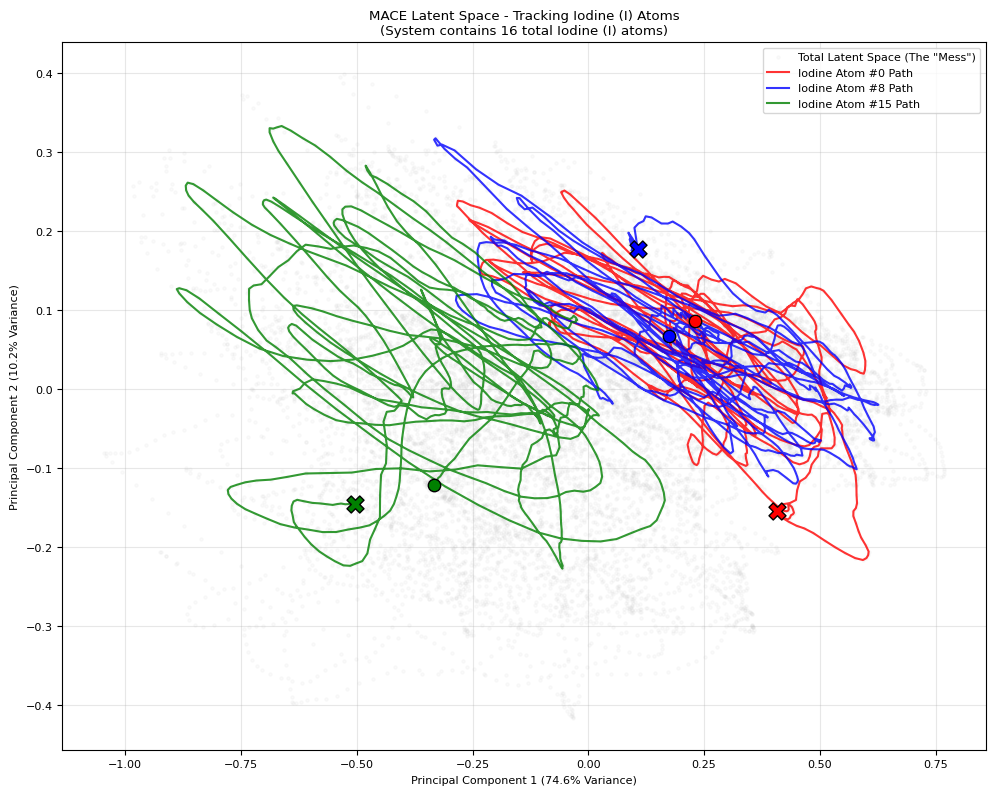

Analysis complete! High-res plot saved to /content/mace_atom_tracking_pca.png


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from ase.io import read
from sklearn.decomposition import PCA
from mace.calculators import MACECalculator
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# File Paths
outcar_file = "/content/drive/MyDrive/MDProject/OUTCAR"
model_path = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/seed3/model_3000_pts_seed3_run-1_stagetwo.model"


calc = MACECalculator(model_paths=model_path, device='cuda', default_dtype='float32')

frames = read(outcar_file, index="::10", format="vasp-out")

target_atomic_number = 53
target_name = "Iodine (I)"

first_frame = frames[0]
total_atoms = len(first_frame)
iodine_count = sum(first_frame.get_atomic_numbers() == target_atomic_number)

print(f"Total atoms in box: {total_atoms}")
print(f"Total {target_name} atoms: {iodine_count}")


time_series_descriptors = []

print(f"Extracting MACE latent descriptors for {target_name} atoms...")
for i, atoms in enumerate(frames):
    atoms.calc = calc
    desc = calc.get_descriptors(atoms)

    # Filter for Iodine
    iodine_mask = (atoms.get_atomic_numbers() == target_atomic_number)
    iodine_desc = desc[iodine_mask]

    time_series_descriptors.append(iodine_desc)
    if i % 50 == 0:
        print(f"Processed frame {i}/{len(frames)}")

# Convert to numpy array
time_series_descriptors = np.array(time_series_descriptors)
T, N_I, F = time_series_descriptors.shape

#  Flatten the data to run PCA, then reshape it back
print(f"Running PCA on {T * N_I} total atomic environments...")
X_flat = time_series_descriptors.reshape(T * N_I, F)

pca = PCA(n_components=2)
X_pca_flat = pca.fit_transform(X_flat)

# Reshape back to 3D so we can easily track individual atoms over time!
X_pca = X_pca_flat.reshape(T, N_I, 2)

#  Plotting the Trajectories
plt.figure(figsize=(10, 8))

# Background: Plot all atoms at all times as a faint gray "map"
plt.scatter(X_pca_flat[:, 0], X_pca_flat[:, 1], c='lightgray', s=5, alpha=0.1, label='Total Latent Space (The "Mess")')

# Foreground: Track 3 distinct Iodine atoms over the entire simulation
colors = ['red', 'blue', 'green']

#  Safely pick the first, middle, and last Iodine atom using our count
atoms_to_track = [0, iodine_count // 2, iodine_count - 1]

for color, atom_idx in zip(colors, atoms_to_track):
    path_x = X_pca[:, atom_idx, 0]
    path_y = X_pca[:, atom_idx, 1]

    # Draw the path
    plt.plot(path_x, path_y, color=color, linewidth=1.5, alpha=0.8, label=f'Iodine Atom #{atom_idx} Path')

    # Highlight the Start (Circle) and End (X) of the path
    plt.scatter(path_x[0], path_y[0], color=color, marker='o', edgecolors='black', s=80, zorder=5)
    plt.scatter(path_x[-1], path_y[-1], color=color, marker='X', edgecolors='black', s=150, zorder=5)

plt.title(f'MACE Latent Space - Tracking {target_name} Atoms\n(System contains {iodine_count} total {target_name} atoms)')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)')
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
save_path = '/content/mace_atom_tracking_pca.png'
plt.savefig(save_path, dpi=300)
plt.show()

print(f"Analysis complete! High-res plot saved to {save_path}")


--- ATOMIC MIGRATION & STABILITY REPORT ---
Iodine Atom # 0:
  - Max distortion reached: 2.48 sigma
  - Time spent inside normal physical limits (2-sigma): 97.2%
----------------------------------------
Iodine Atom # 8:
  - Max distortion reached: 2.74 sigma
  - Time spent inside normal physical limits (2-sigma): 98.7%
----------------------------------------
Iodine Atom #15:
  - Max distortion reached: 3.36 sigma
  - Time spent inside normal physical limits (2-sigma): 80.6%
  -> WARNING: This atom exhibits high mobility or massive structural distortion!
----------------------------------------


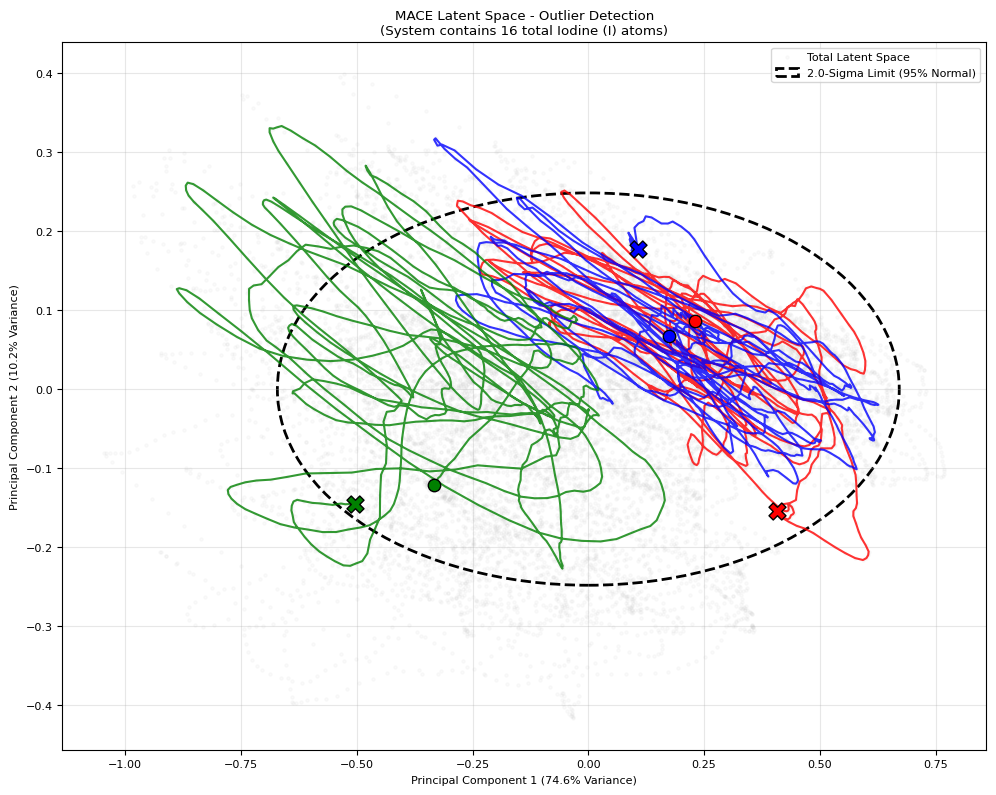

In [ ]:
from matplotlib.patches import Ellipse

# --- QUANTIFICATION ANALYSIS ---
print("\n--- ATOMIC MIGRATION & STABILITY REPORT ---")

# 1. Calculate the Standard Deviation of the total "Physics Cloud"
# Since PCA centers data at (0,0), we just need the std deviation of each axis
std_pc1 = np.std(X_pca_flat[:, 0])
std_pc2 = np.std(X_pca_flat[:, 1])

# We define the "Normal Physical Limit" as 2 standard deviations (approx 95% confidence interval)
sigma_threshold = 2.0

# Re-draw the figure to add boundaries
plt.figure(figsize=(10, 8))
plt.scatter(X_pca_flat[:, 0], X_pca_flat[:, 1], c='lightgray', s=5, alpha=0.1, label='Total Latent Space')

# Draw the 2-sigma elliptical boundary
ellipse = Ellipse((0, 0), width=std_pc1 * 2 * sigma_threshold, height=std_pc2 * 2 * sigma_threshold,
                  edgecolor='black', facecolor='none', linestyle='--', linewidth=2, label=f'{sigma_threshold}-Sigma Limit (95% Normal)')
plt.gca().add_patch(ellipse)

for color, atom_idx in zip(colors, atoms_to_track):
    path_x = X_pca[:, atom_idx, 0]
    path_y = X_pca[:, atom_idx, 1]

    # 2. Calculate the Mahalanobis Distance for this atom at every time step
    # Equation: D = sqrt( (x/std_x)^2 + (y/std_y)^2 )
    distances = np.sqrt((path_x / std_pc1)**2 + (path_y / std_pc2)**2)

    # 3. Quantify how often it stays inside the physical limit
    time_inside = np.sum(distances <= sigma_threshold)
    percent_inside = (time_inside / T) * 100

    max_distance = np.max(distances)

    print(f"Iodine Atom #{atom_idx:>2}:")
    print(f"  - Max distortion reached: {max_distance:.2f} sigma")
    print(f"  - Time spent inside normal physical limits (2-sigma): {percent_inside:.1f}%")
    if percent_inside < 90.0:
        print(f"  -> WARNING: This atom exhibits high mobility or massive structural distortion!")
    print("-" * 40)

    # Re-draw the paths
    plt.plot(path_x, path_y, color=color, linewidth=1.5, alpha=0.8)
    plt.scatter(path_x[0], path_y[0], color=color, marker='o', edgecolors='black', s=80, zorder=5)
    plt.scatter(path_x[-1], path_y[-1], color=color, marker='X', edgecolors='black', s=150, zorder=5)

plt.title(f'MACE Latent Space - Outlier Detection\n(System contains {iodine_count} total {target_name} atoms)')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('/content/mace_quantified_limits.png', dpi=300)
plt.show()

Analysis for all elements in the structure

/usr/local/lib/python3.13/dist-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))


cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Mounted at /content/drive
Loading MACE model...


/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


Loading OUTCAR (extracting every 10th frame)...

--- SYSTEM ATOMIC MAKEUP ---
Total atoms in box: 100
  - Hydrogen (H): 56 atoms
  - Carbon (C): 16 atoms
  - Nitrogen (N): 8 atoms
  - Tin (Sn): 4 atoms
  - Iodine (I): 16 atoms
----------------------------

Extracting MACE latent descriptors for all atoms...
Processed frame 0/1000
Processed frame 50/1000
Processed frame 100/1000
Processed frame 150/1000
Processed frame 200/1000
Processed frame 250/1000
Processed frame 300/1000
Processed frame 350/1000
Processed frame 400/1000
Processed frame 450/1000
Processed frame 500/1000
Processed frame 550/1000
Processed frame 600/1000
Processed frame 650/1000
Processed frame 700/1000
Processed frame 750/1000
Processed frame 800/1000
Processed frame 850/1000
Processed frame 900/1000
Processed frame 950/1000

--- ATOMIC MIGRATION & STABILITY REPORT ---
[Hydrogen (H)]
  Atom # 0: Max distortion 3.33 sigma | 81.7% inside 2-sigma limit
  Atom #28: Max distortion 2.16 sigma | 99.6% inside 2-sigma limit


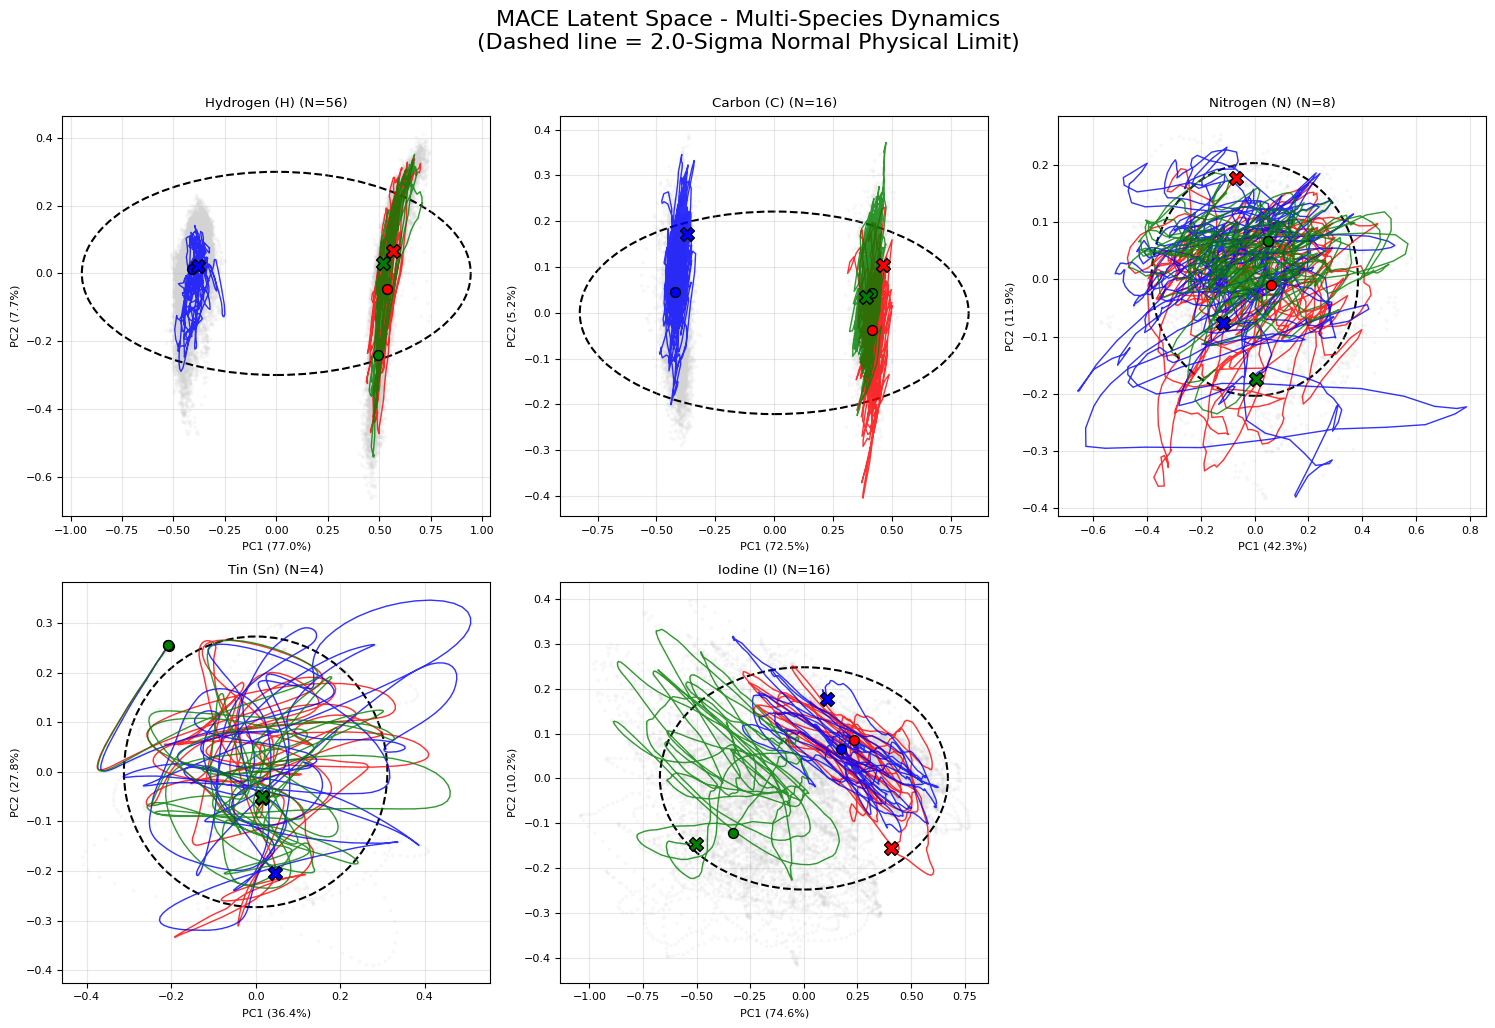


Analysis complete! High-res grid plot saved to /content/mace_multispecies_pca_grid.png


In [ ]:
import os
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from ase.io import read
from sklearn.decomposition import PCA
from mace.calculators import MACECalculator
from google.colab import drive

#  Mount Google Drive
drive.mount('/content/drive')

#  File Paths
outcar_file = "/content/drive/MyDrive/MDProject/OUTCAR"
model_path = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/seed3/model_3000_pts_seed3_run-1_stagetwo.model"

#  Load the Model and OUTCAR
print("Loading MACE model...")
calc = MACECalculator(model_paths=model_path, device='cuda', default_dtype='float32')

print("Loading OUTCAR (extracting every 10th frame)...")
frames = read(outcar_file, index="::10", format="vasp-out")

# Define the dictionary of elements in your system
element_dict = {1: 'Hydrogen (H)', 6: 'Carbon (C)', 7: 'Nitrogen (N)', 50: 'Tin (Sn)', 53: 'Iodine (I)'}

#  Count atoms in the first frame 
first_frame = frames[0]
total_atoms = len(first_frame)
atomic_numbers_in_box = first_frame.get_atomic_numbers()

print(f"\n--- SYSTEM ATOMIC MAKEUP ---")
print(f"Total atoms in box: {total_atoms}")
active_elements = {}
for z, name in element_dict.items():
    count = np.sum(atomic_numbers_in_box == z)
    if count > 0:
        active_elements[z] = {"name": name, "count": count, "descriptors": []}
        print(f"  - {name}: {count} atoms")
print(f"----------------------------\n")

# Extract MACE Descriptors (Optimized: 1 pass per frame)
print(f"Extracting MACE latent descriptors for all atoms...")
for i, atoms in enumerate(frames):
    atoms.calc = calc
    # Extract ALL descriptors at once (Shape: Total_Atoms x Features)
    desc = calc.get_descriptors(atoms)

    # Split the descriptors into their respective element buckets
    z_array = atoms.get_atomic_numbers()
    for z in active_elements.keys():
        mask = (z_array == z)
        active_elements[z]["descriptors"].append(desc[mask])

    if i % 50 == 0:
        print(f"Processed frame {i}/{len(frames)}")

#  Set up the Plotting Grid
num_plots = len(active_elements)
cols = 3
rows = math.ceil(num_plots / cols)

fig, axes = plt.subplots(nrows=rows, ncols=cols, figsize=(5 * cols, 5 * rows))
axes = axes.flatten() # Flatten to loop easily

#  Analyze and Plot Each Element
print("\n--- ATOMIC MIGRATION & STABILITY REPORT ---")
sigma_threshold = 2.0

for idx, (z, data) in enumerate(active_elements.items()):
    ax = axes[idx]
    name = data["name"]
    N_atoms = data["count"]

    # Convert list of arrays to 3D matrix: (Frames, Atoms, Features)
    X_time = np.array(data["descriptors"])
    T, N_z, F = X_time.shape

    # Flatten to run PCA
    X_flat = X_time.reshape(T * N_z, F)
    pca = PCA(n_components=2)
    X_pca_flat = pca.fit_transform(X_flat)

    # Reshape back to 3D for tracking: (Frames, Atoms, 2)
    X_pca = X_pca_flat.reshape(T, N_z, 2)

    # Standard Deviations for Mahalanobis Distance & Ellipse
    std_pc1 = np.std(X_pca_flat[:, 0])
    std_pc2 = np.std(X_pca_flat[:, 1])

    # --- PLOTTING ---
    # Background "Mess"
    ax.scatter(X_pca_flat[:, 0], X_pca_flat[:, 1], c='lightgray', s=3, alpha=0.1)

    # The 2-Sigma Ellipse Boundary
    ellipse = Ellipse((0, 0), width=std_pc1 * 2 * sigma_threshold, height=std_pc2 * 2 * sigma_threshold,
                      edgecolor='black', facecolor='none', linestyle='--', linewidth=1.5)
    ax.add_patch(ellipse)

    # Safely pick up to 3 unique atoms to track
    atoms_to_track = list(np.unique([0, N_atoms // 2, N_atoms - 1]))
    colors = ['red', 'blue', 'green'][:len(atoms_to_track)]

    print(f"[{name}]")
    for color, atom_idx in zip(colors, atoms_to_track):
        path_x = X_pca[:, atom_idx, 0]
        path_y = X_pca[:, atom_idx, 1]

        # Calculate Mahalanobis Distance for this atom
        distances = np.sqrt((path_x / std_pc1)**2 + (path_y / std_pc2)**2)
        percent_inside = np.sum(distances <= sigma_threshold) / T * 100
        max_dist = np.max(distances)

        print(f"  Atom #{atom_idx:>2}: Max distortion {max_dist:.2f} sigma | {percent_inside:.1f}% inside 2-sigma limit")

        # Draw Trajectory
        ax.plot(path_x, path_y, color=color, linewidth=1.0, alpha=0.8)
        ax.scatter(path_x[0], path_y[0], color=color, marker='o', edgecolors='black', s=50, zorder=5) # Start
        ax.scatter(path_x[-1], path_y[-1], color=color, marker='X', edgecolors='black', s=100, zorder=5) # End

    # Annotate Subplot
    ax.set_title(f'{name} (N={N_atoms})')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.grid(True, alpha=0.3)

# Hide any unused subplots (if you have 5 elements, the 6th subplot will be blank)
for idx in range(num_plots, len(axes)):
    fig.delaxes(axes[idx])

plt.suptitle(f'MACE Latent Space - Multi-Species Dynamics\n(Dashed line = {sigma_threshold}-Sigma Normal Physical Limit)', fontsize=16, y=1.02)
plt.tight_layout()

save_path = '/content/mace_multispecies_pca_grid.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nAnalysis complete! High-res grid plot saved to {save_path}")

/usr/local/lib/python3.13/dist-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))


cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Mounted at /content/drive
Loading MACE model...


/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


Loading OUTCAR (extracting every 10th frame)...

--- SYSTEM ATOMIC MAKEUP ---
Total atoms in box: 100
  - Hydrogen (H): 56 atoms
  - Carbon (C): 16 atoms
  - Nitrogen (N): 8 atoms
  - Tin (Sn): 4 atoms
  - Iodine (I): 16 atoms
----------------------------

Extracting MACE latent descriptors for all atoms...
Processed frame 0/1000
Processed frame 50/1000
Processed frame 100/1000
Processed frame 150/1000
Processed frame 200/1000
Processed frame 250/1000
Processed frame 300/1000
Processed frame 350/1000
Processed frame 400/1000
Processed frame 450/1000
Processed frame 500/1000
Processed frame 550/1000
Processed frame 600/1000
Processed frame 650/1000
Processed frame 700/1000
Processed frame 750/1000
Processed frame 800/1000
Processed frame 850/1000
Processed frame 900/1000
Processed frame 950/1000

--- ATOMIC MIGRATION & STABILITY REPORT ---
[Hydrogen (H)]
  Atom # 0: Max distortion 3.27 sigma | 84.1% inside 2-sigma limit
  Atom #28: Max distortion 1.51 sigma | 100.0% inside 2-sigma limit

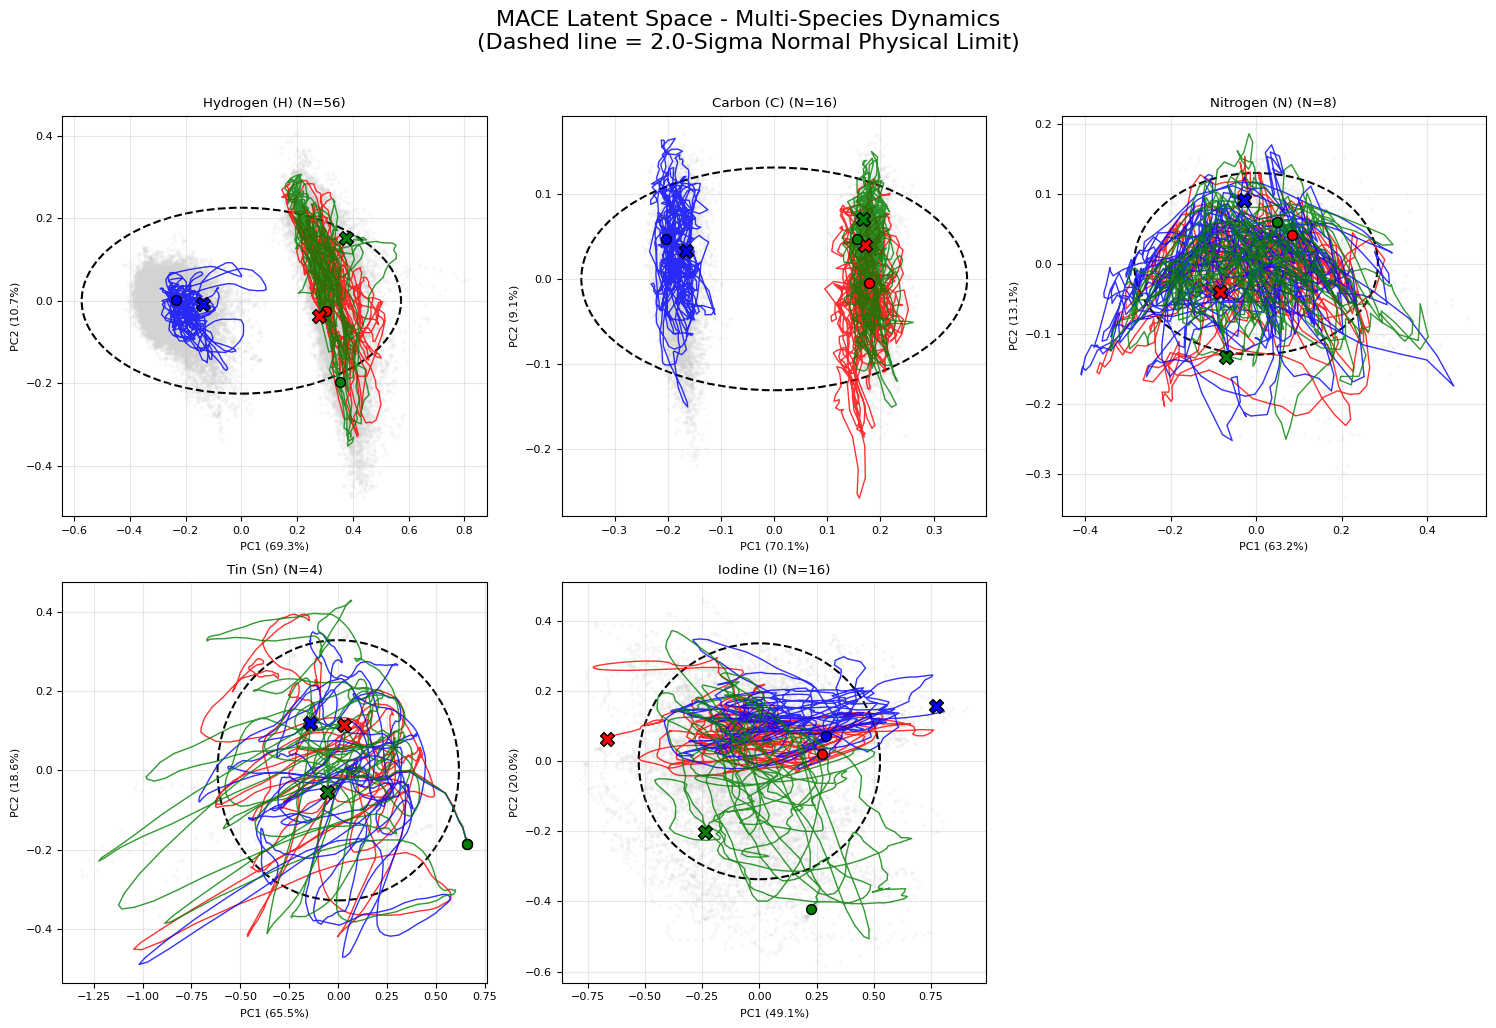


Analysis complete! High-res grid plot saved to /content/mace_multispecies_pca_grid.png


In [ ]:
import os
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from ase.io import read
from sklearn.decomposition import PCA
from mace.calculators import MACECalculator
from google.colab import drive

#  Mount Google Drive
drive.mount('/content/drive')

#  File Paths
outcar_file = "/content/drive/MyDrive/MDProject/OUTCAR"
model_path = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/corr3trueL1/model_3000_pts_corr3L1_run-1_stagetwo.model"

# Load the Model and OUTCAR
print("Loading MACE model...")
calc = MACECalculator(model_paths=model_path, device='cuda', default_dtype='float32')

print("Loading OUTCAR (extracting every 10th frame)...")
frames = read(outcar_file, index="::10", format="vasp-out")

# Define the dictionary of elements in your system
element_dict = {1: 'Hydrogen (H)', 6: 'Carbon (C)', 7: 'Nitrogen (N)', 50: 'Tin (Sn)', 53: 'Iodine (I)'}

first_frame = frames[0]
total_atoms = len(first_frame)
atomic_numbers_in_box = first_frame.get_atomic_numbers()

print(f"Total atoms in box: {total_atoms}")
active_elements = {}
for z, name in element_dict.items():
    count = np.sum(atomic_numbers_in_box == z)
    if count > 0:
        active_elements[z] = {"name": name, "count": count, "descriptors": []}
        print(f"  - {name}: {count} atoms")

print(f"Extracting MACE latent descriptors for all atoms...")
for i, atoms in enumerate(frames):
    atoms.calc = calc
    desc = calc.get_descriptors(atoms)

    # Split the descriptors into their respective element buckets
    z_array = atoms.get_atomic_numbers()
    for z in active_elements.keys():
        mask = (z_array == z)
        active_elements[z]["descriptors"].append(desc[mask])

    if i % 50 == 0:
        print(f"Processed frame {i}/{len(frames)}")

#  Set up the Plotting Grid
num_plots = len(active_elements)
cols = 3
rows = math.ceil(num_plots / cols)

fig, axes = plt.subplots(nrows=rows, ncols=cols, figsize=(5 * cols, 5 * rows))
axes = axes.flatten() # Flatten to loop easily

#  Analyze and Plot Each Element
sigma_threshold = 2.0

for idx, (z, data) in enumerate(active_elements.items()):
    ax = axes[idx]
    name = data["name"]
    N_atoms = data["count"]

    # Convert list of arrays to 3D matrix
    X_time = np.array(data["descriptors"])
    T, N_z, F = X_time.shape

    # Flatten to run PCA
    X_flat = X_time.reshape(T * N_z, F)
    pca = PCA(n_components=2)
    X_pca_flat = pca.fit_transform(X_flat)

    # Reshape back to 3D for tracking: (Frames, Atoms, 2)
    X_pca = X_pca_flat.reshape(T, N_z, 2)

    # Standard Deviations for Mahalanobis Distance & Ellipse
    std_pc1 = np.std(X_pca_flat[:, 0])
    std_pc2 = np.std(X_pca_flat[:, 1])

    # Background "Mess"
    ax.scatter(X_pca_flat[:, 0], X_pca_flat[:, 1], c='lightgray', s=3, alpha=0.1)

    # The 2-Sigma Ellipse Boundary
    ellipse = Ellipse((0, 0), width=std_pc1 * 2 * sigma_threshold, height=std_pc2 * 2 * sigma_threshold,
                      edgecolor='black', facecolor='none', linestyle='--', linewidth=1.5)
    ax.add_patch(ellipse)

    # Safely pick up to 3 unique atoms to track
    atoms_to_track = list(np.unique([0, N_atoms // 2, N_atoms - 1]))
    colors = ['red', 'blue', 'green'][:len(atoms_to_track)]

    print(f"[{name}]")
    for color, atom_idx in zip(colors, atoms_to_track):
        path_x = X_pca[:, atom_idx, 0]
        path_y = X_pca[:, atom_idx, 1]

        # Calculate Mahalanobis Distance for this atom
        distances = np.sqrt((path_x / std_pc1)**2 + (path_y / std_pc2)**2)
        percent_inside = np.sum(distances <= sigma_threshold) / T * 100
        max_dist = np.max(distances)

        print(f"  Atom #{atom_idx:>2}: Max distortion {max_dist:.2f} sigma | {percent_inside:.1f}% inside 2-sigma limit")

        # Draw Trajectory
        ax.plot(path_x, path_y, color=color, linewidth=1.0, alpha=0.8)
        ax.scatter(path_x[0], path_y[0], color=color, marker='o', edgecolors='black', s=50, zorder=5) # Start
        ax.scatter(path_x[-1], path_y[-1], color=color, marker='X', edgecolors='black', s=100, zorder=5) # End

    # Annotate Subplot
    ax.set_title(f'{name} (N={N_atoms})')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.grid(True, alpha=0.3)

# Hide any unused subplots (if you have 5 elements, the 6th subplot will be blank)
for idx in range(num_plots, len(axes)):
    fig.delaxes(axes[idx])

plt.suptitle(f'MACE Latent Space - Multi-Species Dynamics\n(Dashed line = {sigma_threshold}-Sigma Normal Physical Limit)', fontsize=16, y=1.02)
plt.tight_layout()

save_path = '/content/mace_multispecies_pca_grid.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nAnalysis complete! High-res grid plot saved to {save_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading MACE model...


/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


Loading OUTCAR (extracting every 10th frame)...

--- SYSTEM ATOMIC MAKEUP ---
Total atoms in box: 100
  - Hydrogen (H): 56 atoms
  - Carbon (C): 16 atoms
  - Nitrogen (N): 8 atoms
  - Tin (Sn): 4 atoms
  - Iodine (I): 16 atoms
----------------------------

Extracting MACE latent descriptors for all atoms...
Processed frame 0/1000
Processed frame 50/1000
Processed frame 100/1000
Processed frame 150/1000
Processed frame 200/1000
Processed frame 250/1000
Processed frame 300/1000
Processed frame 350/1000
Processed frame 400/1000
Processed frame 450/1000
Processed frame 500/1000
Processed frame 550/1000
Processed frame 600/1000
Processed frame 650/1000
Processed frame 700/1000
Processed frame 750/1000
Processed frame 800/1000
Processed frame 850/1000
Processed frame 900/1000
Processed frame 950/1000

--- ATOMIC MIGRATION & STABILITY REPORT ---
[Hydrogen (H)]
  Atom # 0: Max distortion 2.98 sigma | 93.8% inside 2-sigma limit
  Atom #28: Max distortion 1.95 sigma | 100.0% inside 2-sigma limit

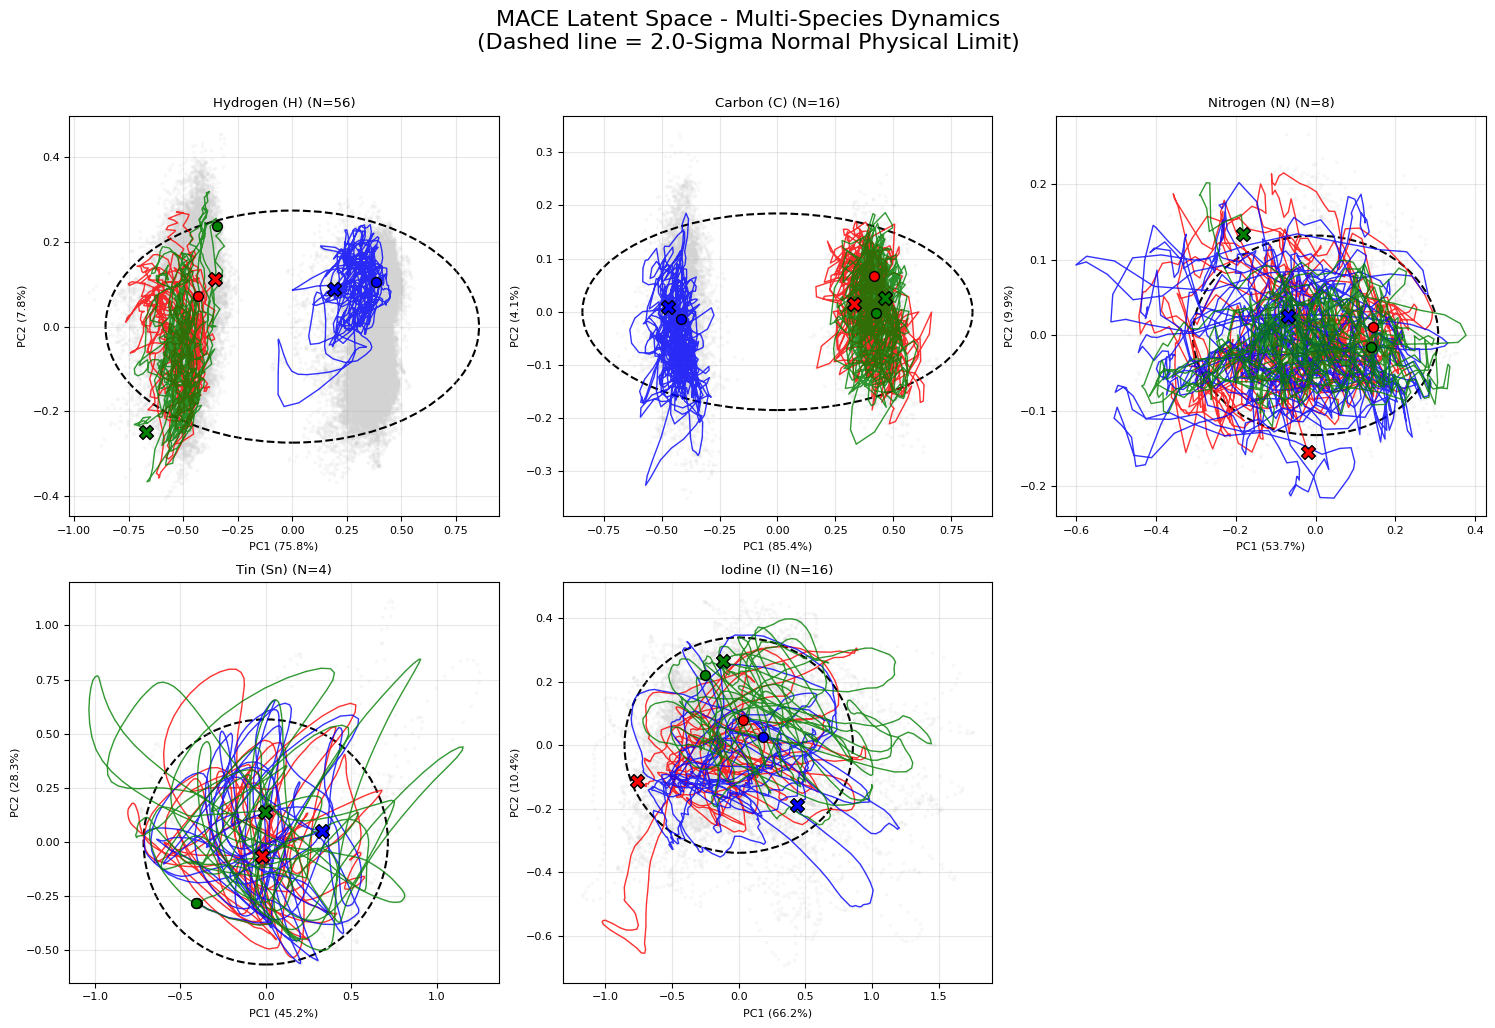


Analysis complete! High-res grid plot saved to /content/mace_multispecies_pca_grid.png


In [ ]:
import os
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from ase.io import read
from sklearn.decomposition import PCA
from mace.calculators import MACECalculator
from google.colab import drive

#  Mount Google Drive
drive.mount('/content/drive')

#  File Paths
outcar_file = "/content/drive/MyDrive/MDProject/OUTCAR"
model_path = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/corr4trueL1/model_3000_pts_corr4L1_run-1_stagetwo.model"

#  Load the Model and OUTCAR
print("Loading MACE model...")
calc = MACECalculator(model_paths=model_path, device='cuda', default_dtype='float32')

print("Loading OUTCAR (extracting every 10th frame)...")
frames = read(outcar_file, index="::10", format="vasp-out")

# Define the dictionary of elements in your system
element_dict = {1: 'Hydrogen (H)', 6: 'Carbon (C)', 7: 'Nitrogen (N)', 50: 'Tin (Sn)', 53: 'Iodine (I)'}

# Count atoms in the first frame
first_frame = frames[0]
total_atoms = len(first_frame)
atomic_numbers_in_box = first_frame.get_atomic_numbers()

print(f"Total atoms in box: {total_atoms}")
active_elements = {}
for z, name in element_dict.items():
    count = np.sum(atomic_numbers_in_box == z)
    if count > 0:
        active_elements[z] = {"name": name, "count": count, "descriptors": []}
        print(f"  - {name}: {count} atoms")


# Extract MACE Descriptors (Optimized: 1 pass per frame)
print(f"Extracting MACE latent descriptors for all atoms...")
for i, atoms in enumerate(frames):
    atoms.calc = calc
    # Extract all descriptors at once (Shape: Total_Atoms x Features)
    desc = calc.get_descriptors(atoms)

    # Split the descriptors into their respective element buckets
    z_array = atoms.get_atomic_numbers()
    for z in active_elements.keys():
        mask = (z_array == z)
        active_elements[z]["descriptors"].append(desc[mask])

    if i % 50 == 0:
        print(f"Processed frame {i}/{len(frames)}")

# Set up the Plotting Grid
num_plots = len(active_elements)
cols = 3
rows = math.ceil(num_plots / cols)

fig, axes = plt.subplots(nrows=rows, ncols=cols, figsize=(5 * cols, 5 * rows))
axes = axes.flatten() # Flatten to loop easily

# Analyze and Plot Each Element
print("\n--- ATOMIC MIGRATION & STABILITY REPORT ---")
sigma_threshold = 2.0

for idx, (z, data) in enumerate(active_elements.items()):
    ax = axes[idx]
    name = data["name"]
    N_atoms = data["count"]

    # Convert list of arrays to 3D matrix: (Frames, Atoms, Features)
    X_time = np.array(data["descriptors"])
    T, N_z, F = X_time.shape

    # Flatten to run PCA
    X_flat = X_time.reshape(T * N_z, F)
    pca = PCA(n_components=2)
    X_pca_flat = pca.fit_transform(X_flat)

    # Reshape back to 3D for tracking: (Frames, Atoms, 2)
    X_pca = X_pca_flat.reshape(T, N_z, 2)

    # Standard Deviations for Mahalanobis Distance & Ellipse
    std_pc1 = np.std(X_pca_flat[:, 0])
    std_pc2 = np.std(X_pca_flat[:, 1])

    # --- PLOTTING ---
    # Background "Mess"
    ax.scatter(X_pca_flat[:, 0], X_pca_flat[:, 1], c='lightgray', s=3, alpha=0.1)

    # The 2-Sigma Ellipse Boundary
    ellipse = Ellipse((0, 0), width=std_pc1 * 2 * sigma_threshold, height=std_pc2 * 2 * sigma_threshold,
                      edgecolor='black', facecolor='none', linestyle='--', linewidth=1.5)
    ax.add_patch(ellipse)

    # Safely pick up to 3 unique atoms to track
    atoms_to_track = list(np.unique([0, N_atoms // 2, N_atoms - 1]))
    colors = ['red', 'blue', 'green'][:len(atoms_to_track)]

    print(f"[{name}]")
    for color, atom_idx in zip(colors, atoms_to_track):
        path_x = X_pca[:, atom_idx, 0]
        path_y = X_pca[:, atom_idx, 1]

        # Calculate Mahalanobis Distance for this atom
        distances = np.sqrt((path_x / std_pc1)**2 + (path_y / std_pc2)**2)
        percent_inside = np.sum(distances <= sigma_threshold) / T * 100
        max_dist = np.max(distances)

        print(f"  Atom #{atom_idx:>2}: Max distortion {max_dist:.2f} sigma | {percent_inside:.1f}% inside 2-sigma limit")

        # Draw Trajectory
        ax.plot(path_x, path_y, color=color, linewidth=1.0, alpha=0.8)
        ax.scatter(path_x[0], path_y[0], color=color, marker='o', edgecolors='black', s=50, zorder=5) # Start
        ax.scatter(path_x[-1], path_y[-1], color=color, marker='X', edgecolors='black', s=100, zorder=5) # End

    # Annotate Subplot
    ax.set_title(f'{name} (N={N_atoms})')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.grid(True, alpha=0.3)

# Hide any unused subplots (if you have 5 elements, the 6th subplot will be blank)
for idx in range(num_plots, len(axes)):
    fig.delaxes(axes[idx])

plt.suptitle(f'MACE Latent Space - Multi-Species Dynamics\n(Dashed line = {sigma_threshold}-Sigma Normal Physical Limit)', fontsize=16, y=1.02)
plt.tight_layout()

save_path = '/content/mace_multispecies_pca_grid.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nAnalysis complete! High-res grid plot saved to {save_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading MACE model...


/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


Loading OUTCAR (extracting every 10th frame)...

--- SYSTEM ATOMIC MAKEUP ---
Total atoms in box: 100
  - Hydrogen (H): 56 atoms
  - Carbon (C): 16 atoms
  - Nitrogen (N): 8 atoms
  - Tin (Sn): 4 atoms
  - Iodine (I): 16 atoms
----------------------------

Extracting MACE latent descriptors for all atoms...
Processed frame 0/1000
Processed frame 50/1000
Processed frame 100/1000
Processed frame 150/1000
Processed frame 200/1000
Processed frame 250/1000
Processed frame 300/1000
Processed frame 350/1000
Processed frame 400/1000
Processed frame 450/1000
Processed frame 500/1000
Processed frame 550/1000
Processed frame 600/1000
Processed frame 650/1000
Processed frame 700/1000
Processed frame 750/1000
Processed frame 800/1000
Processed frame 850/1000
Processed frame 900/1000
Processed frame 950/1000

--- ATOMIC MIGRATION & STABILITY REPORT ---
[Hydrogen (H)]
  Atom # 0: Max distortion 3.06 sigma | 80.7% inside 2-sigma limit
  Atom #28: Max distortion 1.69 sigma | 100.0% inside 2-sigma limit

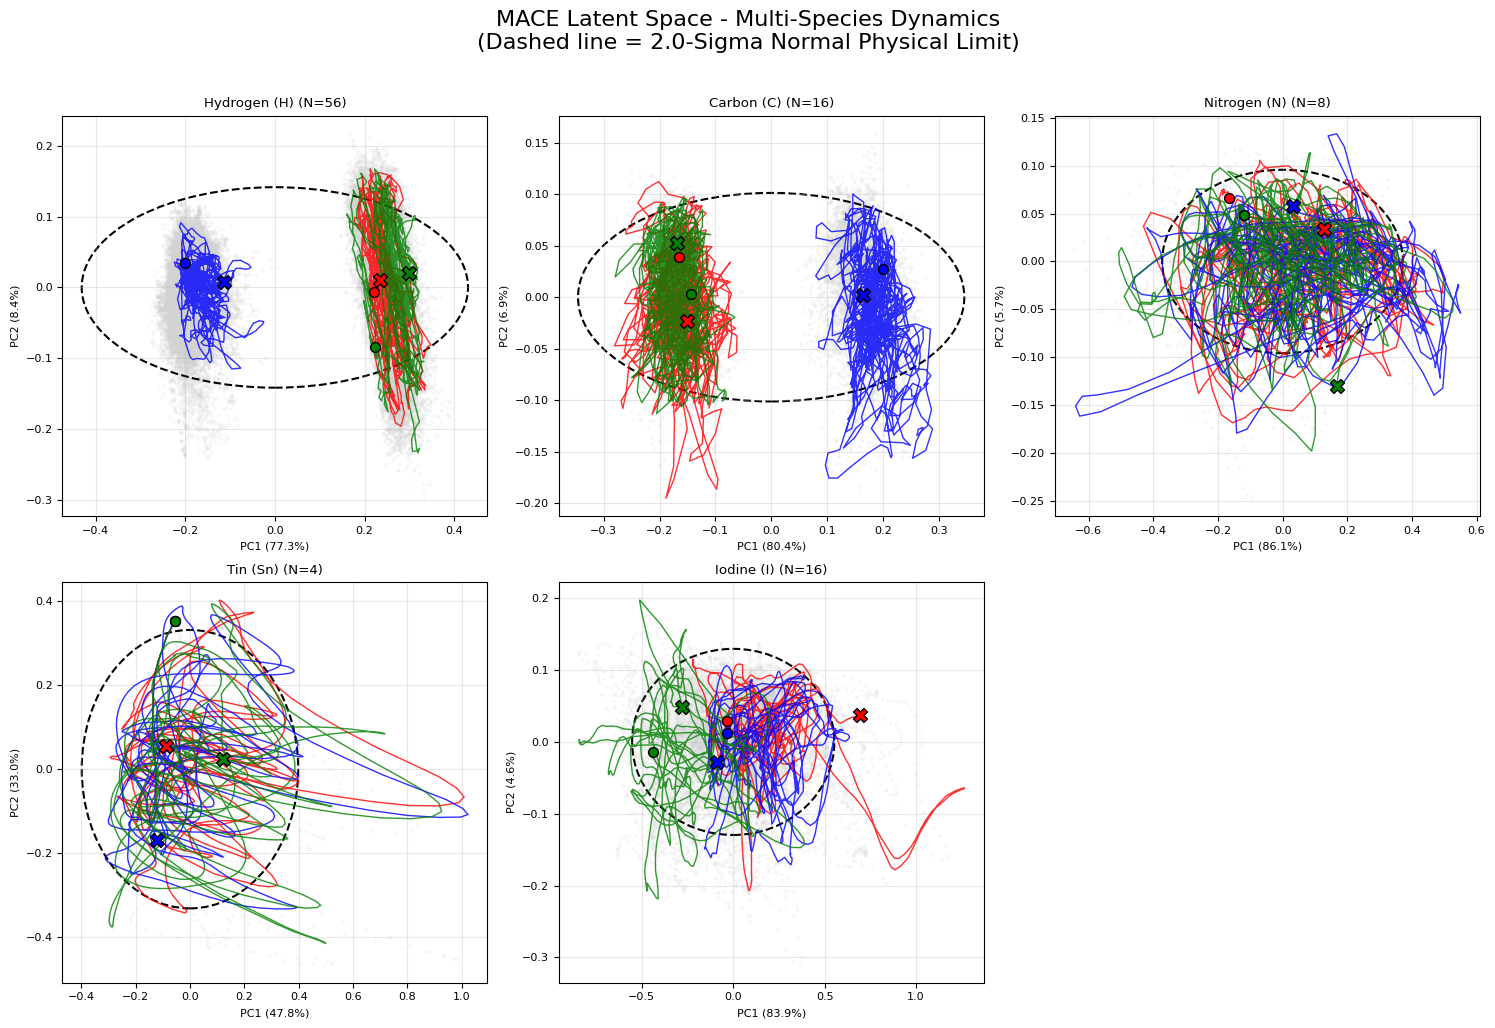


Analysis complete! High-res grid plot saved to /content/mace_multispecies_pca_grid.png


In [ ]:
import os
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from ase.io import read
from sklearn.decomposition import PCA
from mace.calculators import MACECalculator
from google.colab import drive

#  Mount Google Drive
drive.mount('/content/drive')

#  File Paths
outcar_file = "/content/drive/MyDrive/MDProject/OUTCAR"
model_path = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/corr2trueL1/model_3000_pts_corr2L1_run-1_stagetwo.model"

#  Load the Model and OUTCAR
print("Loading MACE model...")
calc = MACECalculator(model_paths=model_path, device='cuda', default_dtype='float32')

print("Loading OUTCAR (extracting every 10th frame)...")
frames = read(outcar_file, index="::10", format="vasp-out")

# Define the dictionary of elements in your system
element_dict = {1: 'Hydrogen (H)', 6: 'Carbon (C)', 7: 'Nitrogen (N)', 50: 'Tin (Sn)', 53: 'Iodine (I)'}

# Count atoms in the first frame 
first_frame = frames[0]
total_atoms = len(first_frame)
atomic_numbers_in_box = first_frame.get_atomic_numbers()

print(f"\n--- SYSTEM ATOMIC MAKEUP ---")
print(f"Total atoms in box: {total_atoms}")
active_elements = {}
for z, name in element_dict.items():
    count = np.sum(atomic_numbers_in_box == z)
    if count > 0:
        active_elements[z] = {"name": name, "count": count, "descriptors": []}
        print(f"  - {name}: {count} atoms")
print(f"----------------------------\n")

#  Extract MACE Descriptors (Optimized: 1 pass per frame)
print(f"Extracting MACE latent descriptors for all atoms...")
for i, atoms in enumerate(frames):
    atoms.calc = calc
    # Extract ALL descriptors at once (Shape: Total_Atoms x Features)
    desc = calc.get_descriptors(atoms)

    # Split the descriptors into their respective element buckets
    z_array = atoms.get_atomic_numbers()
    for z in active_elements.keys():
        mask = (z_array == z)
        active_elements[z]["descriptors"].append(desc[mask])

    if i % 50 == 0:
        print(f"Processed frame {i}/{len(frames)}")

#  Set up the Plotting Grid
num_plots = len(active_elements)
cols = 3
rows = math.ceil(num_plots / cols)

fig, axes = plt.subplots(nrows=rows, ncols=cols, figsize=(5 * cols, 5 * rows))
axes = axes.flatten() # Flatten to loop easily

#  Analyze and Plot Each Element
print("\n--- ATOMIC MIGRATION & STABILITY REPORT ---")
sigma_threshold = 2.0

for idx, (z, data) in enumerate(active_elements.items()):
    ax = axes[idx]
    name = data["name"]
    N_atoms = data["count"]

    # Convert list of arrays to 3D matrix: (Frames, Atoms, Features)
    X_time = np.array(data["descriptors"])
    T, N_z, F = X_time.shape

    # Flatten to run PCA
    X_flat = X_time.reshape(T * N_z, F)
    pca = PCA(n_components=2)
    X_pca_flat = pca.fit_transform(X_flat)

    # Reshape back to 3D for tracking: (Frames, Atoms, 2)
    X_pca = X_pca_flat.reshape(T, N_z, 2)

    # Standard Deviations for Mahalanobis Distance & Ellipse
    std_pc1 = np.std(X_pca_flat[:, 0])
    std_pc2 = np.std(X_pca_flat[:, 1])

    # --- PLOTTING ---
    # Background "Mess"
    ax.scatter(X_pca_flat[:, 0], X_pca_flat[:, 1], c='lightgray', s=3, alpha=0.1)

    # The 2-Sigma Ellipse Boundary
    ellipse = Ellipse((0, 0), width=std_pc1 * 2 * sigma_threshold, height=std_pc2 * 2 * sigma_threshold,
                      edgecolor='black', facecolor='none', linestyle='--', linewidth=1.5)
    ax.add_patch(ellipse)

    # Safely pick up to 3 unique atoms to track
    atoms_to_track = list(np.unique([0, N_atoms // 2, N_atoms - 1]))
    colors = ['red', 'blue', 'green'][:len(atoms_to_track)]

    print(f"[{name}]")
    for color, atom_idx in zip(colors, atoms_to_track):
        path_x = X_pca[:, atom_idx, 0]
        path_y = X_pca[:, atom_idx, 1]

        # Calculate Mahalanobis Distance for this atom
        distances = np.sqrt((path_x / std_pc1)**2 + (path_y / std_pc2)**2)
        percent_inside = np.sum(distances <= sigma_threshold) / T * 100
        max_dist = np.max(distances)

        print(f"  Atom #{atom_idx:>2}: Max distortion {max_dist:.2f} sigma | {percent_inside:.1f}% inside 2-sigma limit")

        # Draw Trajectory
        ax.plot(path_x, path_y, color=color, linewidth=1.0, alpha=0.8)
        ax.scatter(path_x[0], path_y[0], color=color, marker='o', edgecolors='black', s=50, zorder=5) # Start
        ax.scatter(path_x[-1], path_y[-1], color=color, marker='X', edgecolors='black', s=100, zorder=5) # End

    # Annotate Subplot
    ax.set_title(f'{name} (N={N_atoms})')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.grid(True, alpha=0.3)

# Hide any unused subplots (if you have 5 elements, the 6th subplot will be blank)
for idx in range(num_plots, len(axes)):
    fig.delaxes(axes[idx])

plt.suptitle(f'MACE Latent Space - Multi-Species Dynamics\n(Dashed line = {sigma_threshold}-Sigma Normal Physical Limit)', fontsize=16, y=1.02)
plt.tight_layout()

save_path = '/content/mace_multispecies_pca_grid.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nAnalysis complete! High-res grid plot saved to {save_path}")

In [ ]:
! pip install pymbar
! pip install ase
! pip install mace-torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.4/107.4 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 54.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.0/316.0 kB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 387.7/387.7 kB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 222.8/222.8 kB 23.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 346.8/346.8 kB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 457.5/457.5 kB 45.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 66.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.8/62.8 kB 7.8 MB/s eta 0:00:00
  Created wheel for python-hostlist: filename=python_hostlist-2.3.0-py3-none-any.whl size=39523 sha256=90f1a83bcc44eb77fd027920bf1018f55b6a7b7d6a3640c3bd21f0beec17a072
  Stored in directory: /root/.cache/pip/wheels/05/2e/7e/39f980a5a0755f

Force 1000 

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loading MACE model...


/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


Loading OUTCAR (extracting every 10th frame)...

--- SYSTEM ATOMIC MAKEUP ---
Total atoms in box: 100
  - Hydrogen (H): 56 atoms
  - Carbon (C): 16 atoms
  - Nitrogen (N): 8 atoms
  - Tin (Sn): 4 atoms
  - Iodine (I): 16 atoms
----------------------------

Extracting MACE latent descriptors for all atoms...
Processed frame 0/1000
Processed frame 50/1000
Processed frame 100/1000
Processed frame 150/1000
Processed frame 200/1000
Processed frame 250/1000
Processed frame 300/1000
Processed frame 350/1000
Processed frame 400/1000
Processed frame 450/1000
Processed frame 500/1000
Processed frame 550/1000
Processed frame 600/1000
Processed frame 650/1000
Processed frame 700/1000
Processed frame 750/1000
Processed frame 800/1000
Processed frame 850/1000
Processed frame 900/1000
Processed frame 950/1000

--- ATOMIC MIGRATION & STABILITY REPORT ---
[Hydrogen (H)]
  Atom # 0: Max distortion 3.16 sigma | 82.7% inside 2-sigma limit
  Atom #28: Max distortion 2.09 sigma | 99.4% inside 2-sigma limit


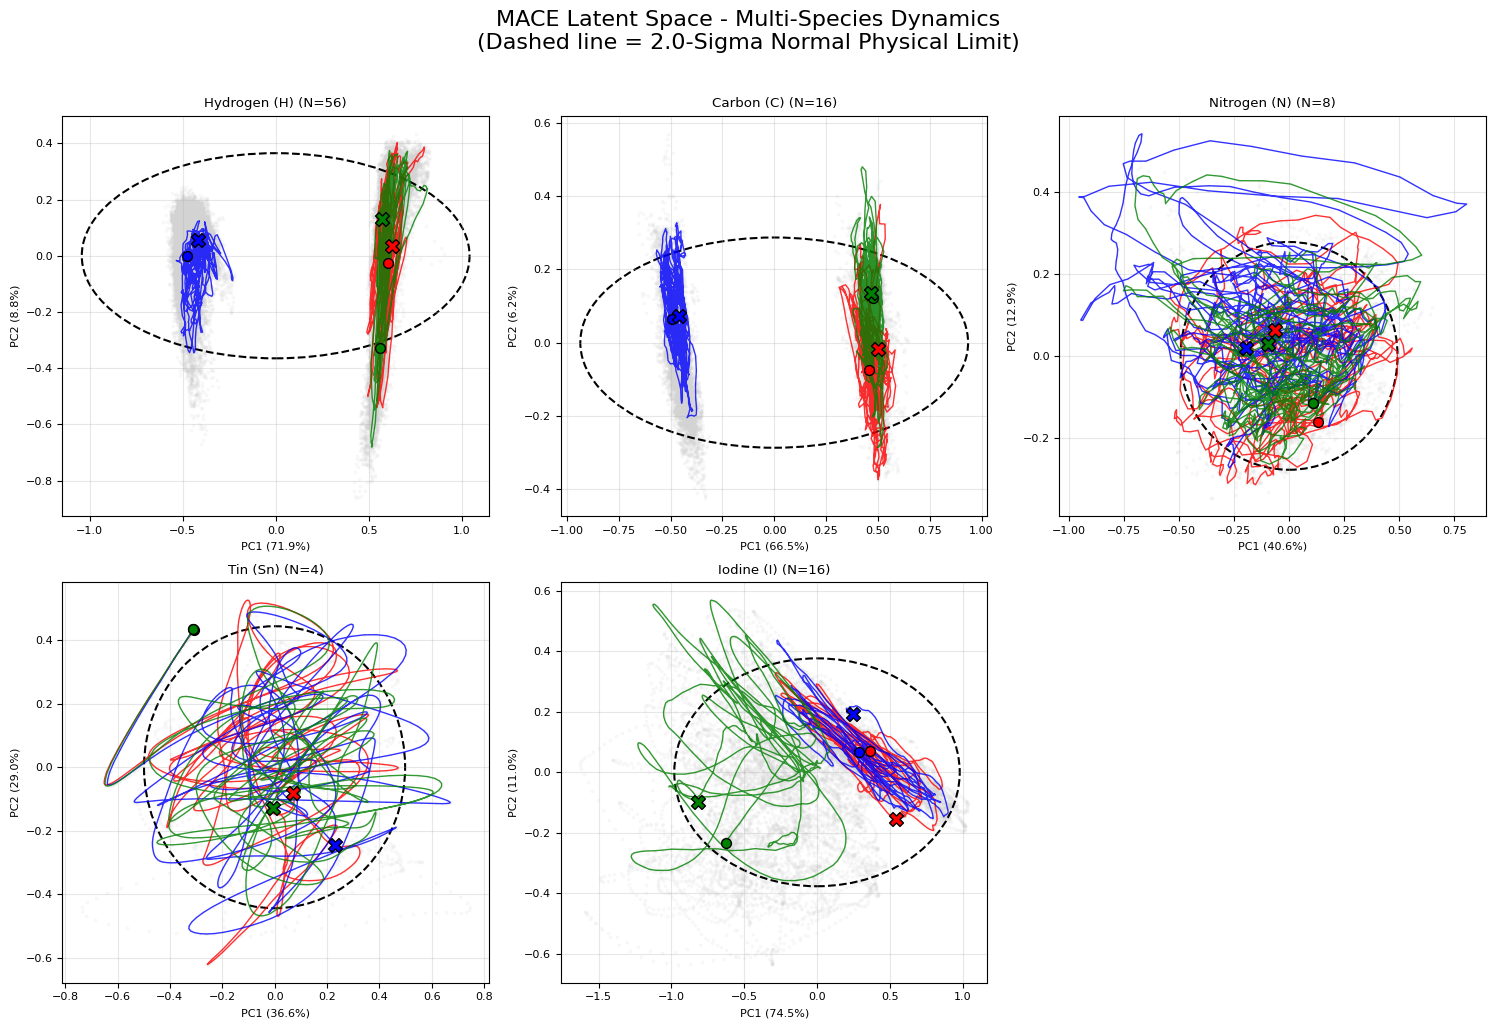


Analysis complete! High-res grid plot saved to /content/mace_multispecies_pca_grid.png


In [ ]:
import os
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from ase.io import read
from sklearn.decomposition import PCA
from mace.calculators import MACECalculator
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. File Paths
outcar_file = "/content/drive/MyDrive/MDProject/OUTCAR"
model_path = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/force1000/model_3000_pts_force1000_run-1_stagetwo.model"

# 3. Load the Model and OUTCAR
print("Loading MACE model...")
calc = MACECalculator(model_paths=model_path, device='cuda', default_dtype='float32')

print("Loading OUTCAR (extracting every 10th frame)...")
frames = read(outcar_file, index="::10", format="vasp-out")

# Define the dictionary of elements in your system
element_dict = {1: 'Hydrogen (H)', 6: 'Carbon (C)', 7: 'Nitrogen (N)', 50: 'Tin (Sn)', 53: 'Iodine (I)'}

# --- SYSTEM CHECK: Count atoms in the first frame ---
first_frame = frames[0]
total_atoms = len(first_frame)
atomic_numbers_in_box = first_frame.get_atomic_numbers()

print(f"\n--- SYSTEM ATOMIC MAKEUP ---")
print(f"Total atoms in box: {total_atoms}")
active_elements = {}
for z, name in element_dict.items():
    count = np.sum(atomic_numbers_in_box == z)
    if count > 0:
        active_elements[z] = {"name": name, "count": count, "descriptors": []}
        print(f"  - {name}: {count} atoms")
print(f"----------------------------\n")

# 4. Extract MACE Descriptors (Optimized: 1 pass per frame)
print(f"Extracting MACE latent descriptors for all atoms...")
for i, atoms in enumerate(frames):
    atoms.calc = calc
    # Extract ALL descriptors at once (Shape: Total_Atoms x Features)
    desc = calc.get_descriptors(atoms)

    # Split the descriptors into their respective element buckets
    z_array = atoms.get_atomic_numbers()
    for z in active_elements.keys():
        mask = (z_array == z)
        active_elements[z]["descriptors"].append(desc[mask])

    if i % 50 == 0:
        print(f"Processed frame {i}/{len(frames)}")

# 5. Set up the Plotting Grid
num_plots = len(active_elements)
cols = 3
rows = math.ceil(num_plots / cols)

fig, axes = plt.subplots(nrows=rows, ncols=cols, figsize=(5 * cols, 5 * rows))
axes = axes.flatten() # Flatten to loop easily

# 6. Analyze and Plot Each Element
print("\n--- ATOMIC MIGRATION & STABILITY REPORT ---")
sigma_threshold = 2.0

for idx, (z, data) in enumerate(active_elements.items()):
    ax = axes[idx]
    name = data["name"]
    N_atoms = data["count"]

    # Convert list of arrays to 3D matrix: (Frames, Atoms, Features)
    X_time = np.array(data["descriptors"])
    T, N_z, F = X_time.shape

    # Flatten to run PCA
    X_flat = X_time.reshape(T * N_z, F)
    pca = PCA(n_components=2)
    X_pca_flat = pca.fit_transform(X_flat)

    # Reshape back to 3D for tracking: (Frames, Atoms, 2)
    X_pca = X_pca_flat.reshape(T, N_z, 2)

    # Standard Deviations for Mahalanobis Distance & Ellipse
    std_pc1 = np.std(X_pca_flat[:, 0])
    std_pc2 = np.std(X_pca_flat[:, 1])

    # --- PLOTTING ---
    # Background "Mess"
    ax.scatter(X_pca_flat[:, 0], X_pca_flat[:, 1], c='lightgray', s=3, alpha=0.1)

    # The 2-Sigma Ellipse Boundary
    ellipse = Ellipse((0, 0), width=std_pc1 * 2 * sigma_threshold, height=std_pc2 * 2 * sigma_threshold,
                      edgecolor='black', facecolor='none', linestyle='--', linewidth=1.5)
    ax.add_patch(ellipse)

    # Safely pick up to 3 unique atoms to track
    atoms_to_track = list(np.unique([0, N_atoms // 2, N_atoms - 1]))
    colors = ['red', 'blue', 'green'][:len(atoms_to_track)]

    print(f"[{name}]")
    for color, atom_idx in zip(colors, atoms_to_track):
        path_x = X_pca[:, atom_idx, 0]
        path_y = X_pca[:, atom_idx, 1]

        # Calculate Mahalanobis Distance for this atom
        distances = np.sqrt((path_x / std_pc1)**2 + (path_y / std_pc2)**2)
        percent_inside = np.sum(distances <= sigma_threshold) / T * 100
        max_dist = np.max(distances)

        print(f"  Atom #{atom_idx:>2}: Max distortion {max_dist:.2f} sigma | {percent_inside:.1f}% inside 2-sigma limit")

        # Draw Trajectory
        ax.plot(path_x, path_y, color=color, linewidth=1.0, alpha=0.8)
        ax.scatter(path_x[0], path_y[0], color=color, marker='o', edgecolors='black', s=50, zorder=5) # Start
        ax.scatter(path_x[-1], path_y[-1], color=color, marker='X', edgecolors='black', s=100, zorder=5) # End

    # Annotate Subplot
    ax.set_title(f'{name} (N={N_atoms})')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.grid(True, alpha=0.3)

# Hide any unused subplots (if you have 5 elements, the 6th subplot will be blank)
for idx in range(num_plots, len(axes)):
    fig.delaxes(axes[idx])

plt.suptitle(f'MACE Latent Space - Multi-Species Dynamics\n(Dashed line = {sigma_threshold}-Sigma Normal Physical Limit)', fontsize=16, y=1.02)
plt.tight_layout()

save_path = '/content/mace_multispecies_pca_grid.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nAnalysis complete! High-res grid plot saved to {save_path}")

Force 10

Mounted at /content/drive
Loading MACE model...


/usr/local/lib/python3.13/dist-packages/mace/calculators/mace.py:226: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  torch.load(f=model_path, map_location=device)


Loading OUTCAR (extracting every 10th frame)...

--- SYSTEM ATOMIC MAKEUP ---
Total atoms in box: 100
  - Hydrogen (H): 56 atoms
  - Carbon (C): 16 atoms
  - Nitrogen (N): 8 atoms
  - Tin (Sn): 4 atoms
  - Iodine (I): 16 atoms
----------------------------

Extracting MACE latent descriptors for all atoms...
Processed frame 0/1000
Processed frame 50/1000
Processed frame 100/1000
Processed frame 150/1000
Processed frame 200/1000
Processed frame 250/1000
Processed frame 300/1000
Processed frame 350/1000
Processed frame 400/1000
Processed frame 450/1000
Processed frame 500/1000
Processed frame 550/1000
Processed frame 600/1000
Processed frame 650/1000
Processed frame 700/1000
Processed frame 750/1000
Processed frame 800/1000
Processed frame 850/1000
Processed frame 900/1000
Processed frame 950/1000

--- ATOMIC MIGRATION & STABILITY REPORT ---
[Hydrogen (H)]
  Atom # 0: Max distortion 3.32 sigma | 82.2% inside 2-sigma limit
  Atom #28: Max distortion 2.18 sigma | 99.7% inside 2-sigma limit


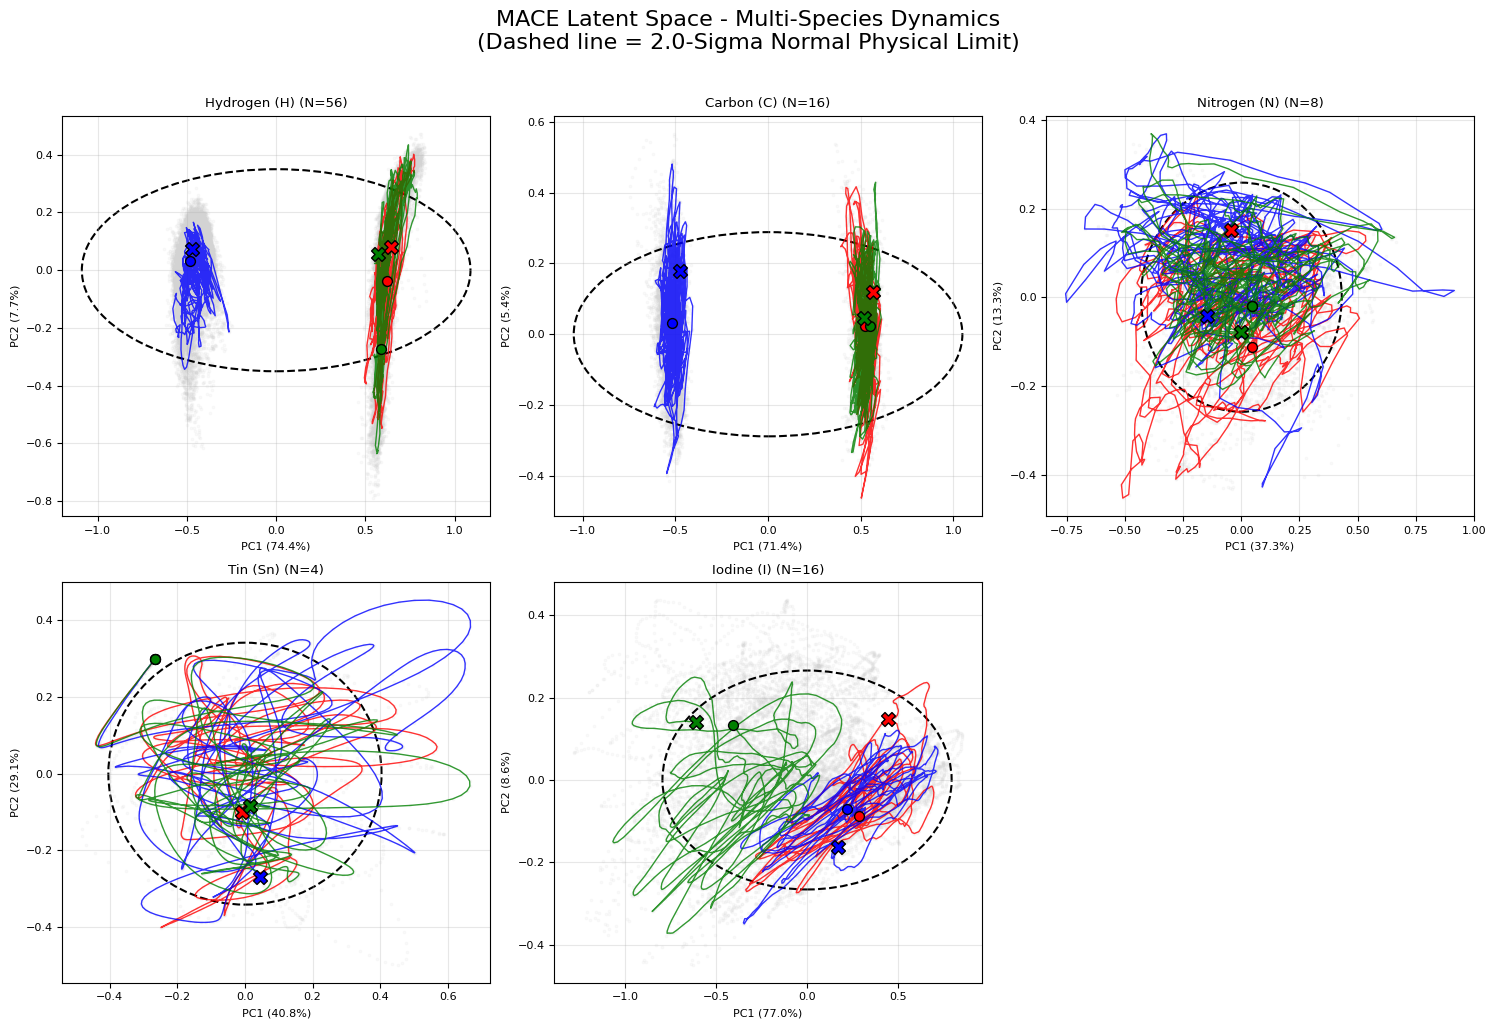


Analysis complete! High-res grid plot saved to /content/mace_multispecies_pca_grid.png


In [ ]:
import os
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from ase.io import read
from sklearn.decomposition import PCA
from mace.calculators import MACECalculator
from google.colab import drive

#  Mount Google Drive
drive.mount('/content/drive')

#  File Paths
outcar_file = "/content/drive/MyDrive/MDProject/OUTCAR"
model_path = "/content/drive/MyDrive/MDProject/new_simulation/1.NVT_300/A.1_10K/checkpoints/force10/model_3000_pts_force10_run-1.model"

#  Load the Model and OUTCAR
print("Loading MACE model...")
calc = MACECalculator(model_paths=model_path, device='cuda', default_dtype='float32')

print("Loading OUTCAR (extracting every 10th frame)...")
frames = read(outcar_file, index="::10", format="vasp-out")

# Define the dictionary of elements in your system
element_dict = {1: 'Hydrogen (H)', 6: 'Carbon (C)', 7: 'Nitrogen (N)', 50: 'Tin (Sn)', 53: 'Iodine (I)'}

# Count atoms in the first frame 
first_frame = frames[0]
total_atoms = len(first_frame)
atomic_numbers_in_box = first_frame.get_atomic_numbers()

print(f"\n--- SYSTEM ATOMIC MAKEUP ---")
print(f"Total atoms in box: {total_atoms}")
active_elements = {}
for z, name in element_dict.items():
    count = np.sum(atomic_numbers_in_box == z)
    if count > 0:
        active_elements[z] = {"name": name, "count": count, "descriptors": []}
        print(f"  - {name}: {count} atoms")


#  Extract MACE Descriptors (Optimized: 1 pass per frame)
print(f"Extracting MACE latent descriptors for all atoms...")
for i, atoms in enumerate(frames):
    atoms.calc = calc
    # Extract ALL descriptors at once (Shape: Total_Atoms x Features)
    desc = calc.get_descriptors(atoms)

    # Split the descriptors into their respective element buckets
    z_array = atoms.get_atomic_numbers()
    for z in active_elements.keys():
        mask = (z_array == z)
        active_elements[z]["descriptors"].append(desc[mask])

    if i % 50 == 0:
        print(f"Processed frame {i}/{len(frames)}")

#  Set up the Plotting Grid
num_plots = len(active_elements)
cols = 3
rows = math.ceil(num_plots / cols)

fig, axes = plt.subplots(nrows=rows, ncols=cols, figsize=(5 * cols, 5 * rows))
axes = axes.flatten() # Flatten to loop easily

# Analyze and Plot Each Element
print("\n--- ATOMIC MIGRATION & STABILITY REPORT ---")
sigma_threshold = 2.0

for idx, (z, data) in enumerate(active_elements.items()):
    ax = axes[idx]
    name = data["name"]
    N_atoms = data["count"]

    # Convert list of arrays to 3D matrix: (Frames, Atoms, Features)
    X_time = np.array(data["descriptors"])
    T, N_z, F = X_time.shape

    # Flatten to run PCA
    X_flat = X_time.reshape(T * N_z, F)
    pca = PCA(n_components=2)
    X_pca_flat = pca.fit_transform(X_flat)

    # Reshape back to 3D for tracking: (Frames, Atoms, 2)
    X_pca = X_pca_flat.reshape(T, N_z, 2)

    # Standard Deviations for Mahalanobis Distance & Ellipse
    std_pc1 = np.std(X_pca_flat[:, 0])
    std_pc2 = np.std(X_pca_flat[:, 1])

    # --- PLOTTING ---
    # Background "Mess"
    ax.scatter(X_pca_flat[:, 0], X_pca_flat[:, 1], c='lightgray', s=3, alpha=0.1)

    # The 2-Sigma Ellipse Boundary
    ellipse = Ellipse((0, 0), width=std_pc1 * 2 * sigma_threshold, height=std_pc2 * 2 * sigma_threshold,
                      edgecolor='black', facecolor='none', linestyle='--', linewidth=1.5)
    ax.add_patch(ellipse)

    # Safely pick up to 3 unique atoms to track
    atoms_to_track = list(np.unique([0, N_atoms // 2, N_atoms - 1]))
    colors = ['red', 'blue', 'green'][:len(atoms_to_track)]

    print(f"[{name}]")
    for color, atom_idx in zip(colors, atoms_to_track):
        path_x = X_pca[:, atom_idx, 0]
        path_y = X_pca[:, atom_idx, 1]

        # Calculate Mahalanobis Distance for this atom
        distances = np.sqrt((path_x / std_pc1)**2 + (path_y / std_pc2)**2)
        percent_inside = np.sum(distances <= sigma_threshold) / T * 100
        max_dist = np.max(distances)

        print(f"  Atom #{atom_idx:>2}: Max distortion {max_dist:.2f} sigma | {percent_inside:.1f}% inside 2-sigma limit")

        # Draw Trajectory
        ax.plot(path_x, path_y, color=color, linewidth=1.0, alpha=0.8)
        ax.scatter(path_x[0], path_y[0], color=color, marker='o', edgecolors='black', s=50, zorder=5) # Start
        ax.scatter(path_x[-1], path_y[-1], color=color, marker='X', edgecolors='black', s=100, zorder=5) # End

    # Annotate Subplot
    ax.set_title(f'{name} (N={N_atoms})')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.grid(True, alpha=0.3)

# Hide any unused subplots (if you have 5 elements, the 6th subplot will be blank)
for idx in range(num_plots, len(axes)):
    fig.delaxes(axes[idx])

plt.suptitle(f'MACE Latent Space - Multi-Species Dynamics\n(Dashed line = {sigma_threshold}-Sigma Normal Physical Limit)', fontsize=16, y=1.02)
plt.tight_layout()

save_path = '/content/mace_multispecies_pca_grid.png'
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nAnalysis complete! High-res grid plot saved to {save_path}")